# 03 — Modelagem Preditiva
## Dado as features de um post, quanto Reach ele terá?

Modelos testados:
1. **Linear Regression** (baseline)
2. **Ridge / Lasso** (regularizados)
3. **Random Forest**
4. **Gradient Boosting**

Avaliação: 5-fold CV com R², MAE e MAPE

In [ ]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.model_selection import cross_validate, KFold
from sklearn.metrics import mean_absolute_error, r2_score, make_scorer
from sklearn.pipeline import Pipeline

PROJECT_ROOT = Path.cwd().parent.parent
sys.path.insert(0, str(PROJECT_ROOT))

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["figure.dpi"] = 100

df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "general_dataset.parquet")
reels = df[df["post_type"] == "REEL"].copy()
print(f"Reels: {len(reels)} posts")

Reels: 116 posts


## 1. Preparar features (mesmo encoding do notebook 02)

In [2]:
num_features = [
    "video_duration_sec", "cuts_per_minute", "speech_pacing_wpm",
    "image_quality_score", "curiosity_gap_level", "first_frame_scroll_stop_score",
    "creator_camera_presence_score", "educational_density",
    "controversy_level", "overall_provocation_score",
    "caption_length_chars", "hashtag_count", "account_mentions_count",
]

cat_features = [
    "aspect_ratio", "text_overlay_presence", "dominant_color_palette",
    "lighting_type", "camera_movement_style", "hook_visual_technique",
    "visual_format_type", "transition_style", "face_presence",
    "zoom_effect_used", "thumbnail_composition",
    "audio_hook_type", "text_hook_on_screen", "pattern_interrupt_type",
    "opening_emotion_conveyed", "hook_delivery_speed",
    "direct_viewer_address", "bait_and_reveal_structure",
    "opening_subject_framing", "people_count", "primary_person_age_range",
    "eye_contact_with_camera", "dominant_facial_expression",
    "body_language_energy", "appearance_style",
    "audio_source_type", "voice_tone_energy", "background_music_mood",
    "music_beat_sync", "voice_to_music_balance", "audio_caption_availability",
    "content_category", "narrative_structure", "value_proposition_type",
    "cta_type", "content_originality", "emotional_arc",
    "target_audience_intent", "information_pacing",
    "skin_exposure_level", "hook_sensuality_level", "suggestive_body_language",
    "innuendo_in_text", "caption_first_line_hook", "caption_tone", "emoji_density",
]

available_cat = [f for f in cat_features if f in reels.columns and reels[f].notna().sum() > 50]
available_num = [f for f in num_features if f in reels.columns and reels[f].notna().sum() > 50]
available = available_num + available_cat

X = reels[available].copy()
enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
X[available_cat] = enc.fit_transform(X[available_cat].fillna("__MISSING__"))
X[available_num] = X[available_num].fillna(X[available_num].median())
X_arr = X.values

target_metrics = ["reach", "views", "likes", "shares", "saved"]
print(f"Features: {X.shape[1]} | Reels: {X.shape[0]}")

Features: 59 | Reels: 116


## 2. Comparar Modelos (5-fold CV)

In [3]:
def mape_scorer(y_true, y_pred):
    mask = y_true != 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

models = {
    "Linear Regression": Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
    "Ridge (α=100)": Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=100))]),
    "Lasso (α=10)": Pipeline([("scaler", StandardScaler()), ("model", Lasso(alpha=10, max_iter=5000))]),
    "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=8, min_samples_leaf=5, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, max_depth=4, learning_rate=0.05,
                                                    min_samples_leaf=5, random_state=42),
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "r2": "r2",
    "mae": "neg_mean_absolute_error",
    "mape": make_scorer(mape_scorer, greater_is_better=False),
}

results_all = {}

for metric in target_metrics:
    y = reels[metric].values
    results = {}
    
    for name, model in models.items():
        cv_res = cross_validate(model, X_arr, y, cv=cv, scoring=scoring, n_jobs=-1)
        results[name] = {
            "R²": cv_res["test_r2"].mean(),
            "R² ±": cv_res["test_r2"].std(),
            "MAE": -cv_res["test_mae"].mean(),
            "MAPE %": -cv_res["test_mape"].mean(),
        }
    
    results_all[metric] = pd.DataFrame(results).T
    
    print(f"\n{'='*60}")
    print(f"TARGET: {metric.upper()}")
    print(f"{'='*60}")
    print(results_all[metric].round(3).to_string())


TARGET: REACH
                        R²     R² ±        MAE    MAPE %
Linear Regression -440.709  813.247  26769.458  1228.962
Ridge (α=100)      -26.495   46.452  10147.021   343.722
Lasso (α=10)      -418.341  770.443  26205.248  1198.110
Random Forest      -24.039   47.054   8101.131   209.194
Gradient Boosting -180.032  355.633  11855.203   383.827



TARGET: VIEWS
                        R²      R² ±        MAE    MAPE %
Linear Regression -539.490  1000.939  35190.736  1317.801
Ridge (α=100)      -32.123    56.768  13321.518   368.382
Lasso (α=10)      -518.450   960.487  34620.204  1292.490
Random Forest      -29.428    57.801  10498.924   217.979
Gradient Boosting -225.977   447.695  14929.908   374.990



TARGET: LIKES
                        R²      R² ±       MAE    MAPE %
Linear Regression -877.337  1708.278  3024.651  3187.941
Ridge (α=100)      -68.595   132.949  1165.870   976.415
Lasso (α=10)      -573.694  1110.592  2623.510  2867.809
Random Forest      -37.073    73.391   884.863   522.105
Gradient Boosting -327.198   650.522  1372.990  1205.383



TARGET: SHARES
                        R²     R² ±       MAE    MAPE %
Linear Regression -258.315  301.532  1034.470  7893.202
Ridge (α=100)      -17.385   16.673   361.801  2148.874
Lasso (α=10)      -116.052  118.095   723.169  5876.698
Random Forest      -15.367   23.297   299.731  1056.377
Gradient Boosting  -69.628  116.078   423.064  1724.036



TARGET: SAVED
                       R²     R² ±      MAE    MAPE %
Linear Regression -64.946  101.500  183.985  1969.152
Ridge (α=100)      -5.698    8.885   72.568   650.347
Lasso (α=10)      -12.514   20.614   82.413   702.688
Random Forest      -2.471    4.643   55.014   345.399
Gradient Boosting -21.350   41.017   77.936   722.293


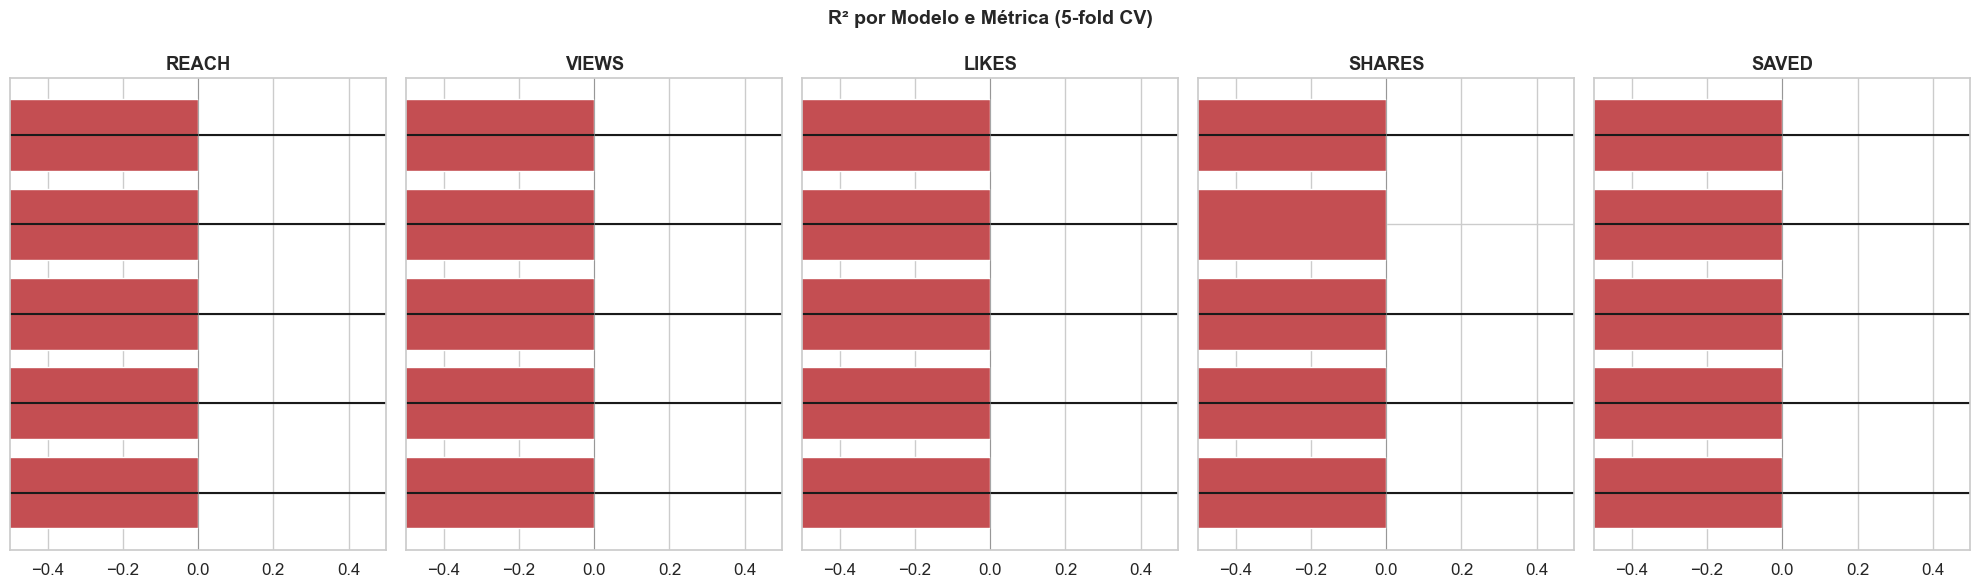

In [4]:
fig, axes = plt.subplots(1, len(target_metrics), figsize=(20, 6), sharey=True)

for ax, metric in zip(axes, target_metrics):
    r2_vals = results_all[metric]["R²"]
    r2_err = results_all[metric]["R² ±"]
    colors = ["#C44E52" if v < 0 else "#55A868" if v > 0.1 else "#CCBB44" for v in r2_vals]
    ax.barh(range(len(r2_vals)), r2_vals, xerr=r2_err, color=colors, edgecolor="white", capsize=4)
    ax.set_yticks(range(len(r2_vals)))
    if ax == axes[0]:
        ax.set_yticklabels(r2_vals.index, fontsize=10)
    else:
        ax.set_yticklabels([])
    ax.axvline(0, color="gray", lw=0.5)
    ax.set_title(metric.upper(), fontweight="bold")
    ax.set_xlim(-0.5, 0.5)
    ax.invert_yaxis()

fig.suptitle("R² por Modelo e Métrica (5-fold CV)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 3. Melhor modelo: Actual vs Predicted

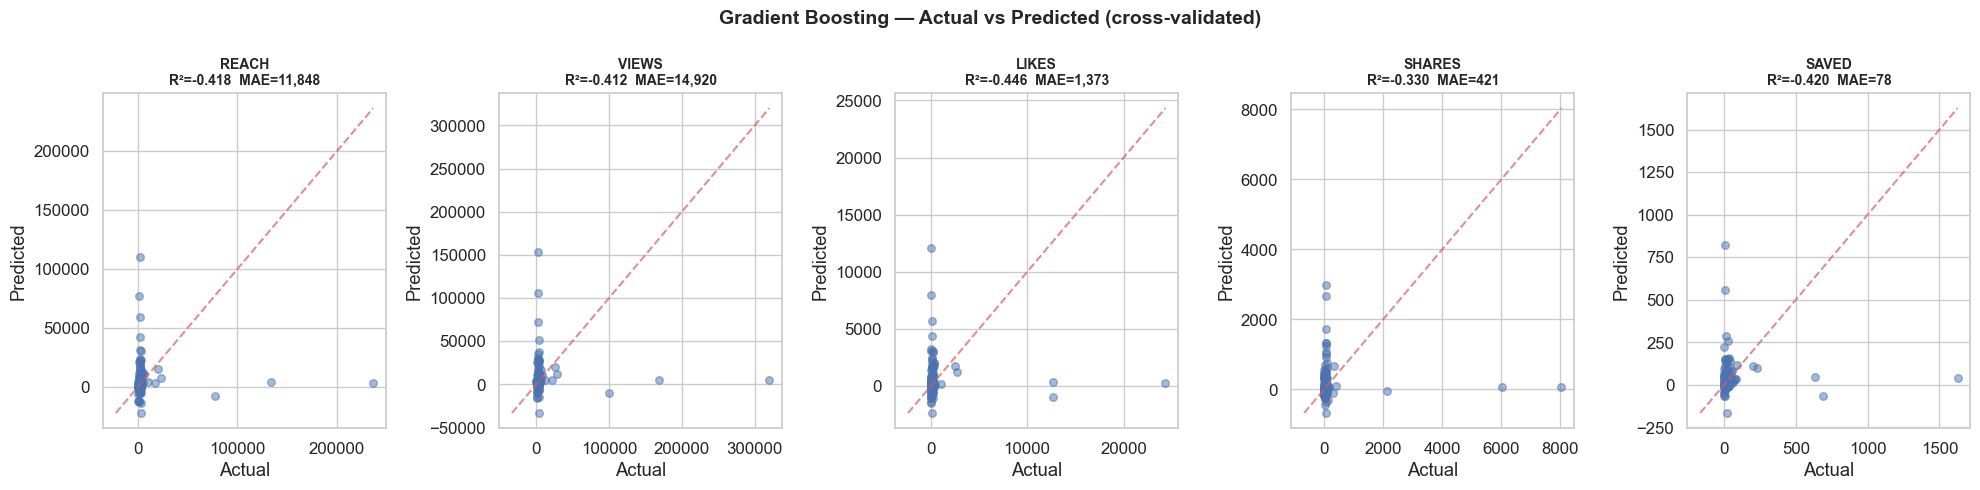

In [5]:
from sklearn.model_selection import cross_val_predict

fig, axes = plt.subplots(1, len(target_metrics), figsize=(20, 5))
best_model = GradientBoostingRegressor(n_estimators=200, max_depth=4, learning_rate=0.05,
                                        min_samples_leaf=5, random_state=42)

for ax, metric in zip(axes, target_metrics):
    y = reels[metric].values
    y_pred = cross_val_predict(best_model, X_arr, y, cv=cv)
    
    r2 = r2_score(y, y_pred)
    mae = mean_absolute_error(y, y_pred)
    
    ax.scatter(y, y_pred, alpha=0.5, s=30, c="#4C72B0")
    lims = [min(y.min(), y_pred.min()), max(y.max(), y_pred.max())]
    ax.plot(lims, lims, "r--", lw=1.5, alpha=0.7)
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")
    ax.set_title(f"{metric.upper()}\nR²={r2:.3f}  MAE={mae:,.0f}", fontweight="bold", fontsize=10)

fig.suptitle("Gradient Boosting — Actual vs Predicted (cross-validated)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 4. Análise de erros: quais posts o modelo erra mais?

In [6]:
y_reach = reels["reach"].values
y_pred_reach = cross_val_predict(best_model, X_arr, y_reach, cv=cv)

error_df = reels[["timestamp", "date_br", "reach", "content_category", "narrative_structure",
                   "video_duration_sec", "caption"]].copy()
error_df["predicted"] = y_pred_reach
error_df["error"] = error_df["reach"] - error_df["predicted"]
error_df["abs_error"] = error_df["error"].abs()
error_df["pct_error"] = (error_df["error"] / error_df["reach"] * 100).round(1)

print("Top 10 posts onde o modelo SUBESTIMOU (virais inesperados):")
print("-" * 80)
under = error_df.nlargest(10, "error")
for _, r in under.iterrows():
    caption_preview = str(r["caption"])[:60].replace("\n", " ")
    print(f"  Reach={r['reach']:>8,.0f}  Pred={r['predicted']:>8,.0f}  "
          f"Erro={r['error']:>+8,.0f}  {r['content_category']:>20s}  \"{caption_preview}...\"")

print(f"\nTop 10 posts onde o modelo SUPERESTIMOU (flopped):")
print("-" * 80)
over = error_df.nsmallest(10, "error")
for _, r in over.iterrows():
    caption_preview = str(r["caption"])[:60].replace("\n", " ")
    print(f"  Reach={r['reach']:>8,.0f}  Pred={r['predicted']:>8,.0f}  "
          f"Erro={r['error']:>+8,.0f}  {r['content_category']:>20s}  \"{caption_preview}...\"")

Top 10 posts onde o modelo SUBESTIMOU (virais inesperados):
--------------------------------------------------------------------------------
  Reach= 236,477  Pred=   3,477  Erro=+233,000  motivation_inspiration  "<caption removed>"
  Reach= 133,973  Pred=   4,121  Erro=+129,852       news_commentary  "<caption removed>"
  Reach=  77,252  Pred=  -7,173  Erro= +84,425      opinion_hot_take  "<caption removed>"
  Reach=   2,988  Pred= -21,820  Erro= +24,808        personal_story  "<caption removed>"
  Reach=   3,145  Pred= -13,456  Erro= +16,601      educational_tips  "<caption removed>"
  Reach=  23,111  Pred=   8,186  Erro= +14,925      opinion_hot_take  "<caption removed>"
  Reach=  17,625  Pred=   3,838  Erro= +13,787      educational_tips  "<caption removed>"
  Reach=   1,221  Pred= -12,338  Erro= +13,559      educational_tips  "<caption removed>"
  Reach=   1,595  Pred= -11,913  Erro= +13,508       news_commentary  "<caption removed>"
  Reach=   1,410  Pred= -11,546  Erro= +12,956 

## 5. Resumo

In [7]:
print("=" * 60)
print("RESUMO DA MODELAGEM")
print("=" * 60)

print("\nMelhor R² por métrica (Gradient Boosting, 5-fold CV):")
for metric in target_metrics:
    r2 = results_all[metric].loc["Gradient Boosting", "R²"]
    mae = results_all[metric].loc["Gradient Boosting", "MAE"]
    mape = results_all[metric].loc["Gradient Boosting", "MAPE %"]
    print(f"  {metric.upper():>8s}:  R²={r2:.3f}  MAE={mae:,.0f}  MAPE={mape:.1f}%")

print(f"""
Interpretação:
- R² positivo = modelo capta algum sinal das features
- R² negativo = features sozinhas não explicam a métrica (fatores externos dominam)
- MAPE alto = erro percentual grande (normal com distribuição muito assimétrica)

Limitações:
- Dataset pequeno (116 Reels) limita a capacidade de generalização
- Viralidade depende de fatores externos (algoritmo, timing, tendências)
- Features são proxies — a mesma feature pode ter impacto diferente por contexto

Próximo passo: clustering para identificar "tipos" de conteúdo com perfis distintos
""")

RESUMO DA MODELAGEM

Melhor R² por métrica (Gradient Boosting, 5-fold CV):
     REACH:  R²=-180.032  MAE=11,855  MAPE=383.8%
     VIEWS:  R²=-225.977  MAE=14,930  MAPE=375.0%
     LIKES:  R²=-327.198  MAE=1,373  MAPE=1205.4%
    SHARES:  R²=-69.628  MAE=423  MAPE=1724.0%
     SAVED:  R²=-21.350  MAE=78  MAPE=722.3%

Interpretação:
- R² positivo = modelo capta algum sinal das features
- R² negativo = features sozinhas não explicam a métrica (fatores externos dominam)
- MAPE alto = erro percentual grande (normal com distribuição muito assimétrica)

Limitações:
- Dataset pequeno (116 Reels) limita a capacidade de generalização
- Viralidade depende de fatores externos (algoritmo, timing, tendências)
- Features são proxies — a mesma feature pode ter impacto diferente por contexto

Próximo passo: clustering para identificar "tipos" de conteúdo com perfis distintos

